# CuPy numerical libraries: sparse matrix products

Start with a tridiagonal matrix in compressed sparse row (CSR) form. Compute $y=Ax$, then $Y=AX$ for several vectors at once, and finally $S=AA$ without converting the full matrix to dense storage. Check every result with SciPy.

Run cells in order in a Google Colab GPU runtime. All figures and printouts stay in the notebook; no result files are exported. This is an introductory correctness experiment, not a CPU/GPU speed benchmark.

## 1. Prepare Colab

Select **Runtime → Change runtime type → GPU**. The checks inspect the remote Linux runtime. The toolkit version selects the binary package only if CuPy is absent; an existing installation is retained.

In [1]:
!nvidia-smi
!nvcc --version

Sun Oct 18 07:12:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Use the existing CuPy installation when available. The next cell installs a CUDA-specific binary package **only if CuPy is absent**, selecting CUDA 12 or 13 from the installed toolkit. It does not install PyCUDA or a notebook extension. Do not install multiple CuPy packages in the same environment.

If an existing CuPy installation fails to import, use a fresh Colab GPU runtime before proceeding. For other environments, follow the [CuPy installation guide](https://docs.cupy.dev/en/stable/install.html).

In [2]:
import importlib.util
import re
import subprocess
import sys

if importlib.util.find_spec("cupy") is None:
    toolkit_info = subprocess.check_output(
        ["nvcc", "--version"], text=True
    )
    match = re.search(r"release\s+(\d+)\.", toolkit_info)
    if match is None or int(match.group(1)) not in (12, 13):
        raise RuntimeError("Use a Colab GPU runtime with CUDA 12 or 13, or follow the CuPy installation guide.")
    package = f"cupy-cuda{match.group(1)}x"
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])
    print("Installed:", package)
else:
    print("Using the existing CuPy installation.")

Using the existing CuPy installation.


## 2. Imports and validation

Double precision makes the numerical comparisons easier to interpret. Inputs are identical for CPU and GPU; floating-point results are compared with tolerances, not required to match bit for bit. CuPy does not use the CPU as a fallback in this notebook.

In [3]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
import scipy
import scipy.sparse as sp
import cupyx.scipy.sparse as cpsparse

if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("Select a GPU runtime in Colab.")
cp.cuda.Device(0).use()
name = cp.cuda.runtime.getDeviceProperties(0)["name"]
if isinstance(name, bytes):
    name = name.decode()
print("GPU:", name)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__, "CuPy:", cp.__version__)
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})

GPU: Tesla T4
Python: 3.13.15 NumPy: 2.1.3 CuPy: 14.0.1


In [4]:
def check(label, result, reference, rtol=1e-11, atol=1e-11):
    assert result.shape == reference.shape, (result.shape, reference.shape)
    assert result.dtype == reference.dtype, (result.dtype, reference.dtype)
    if not np.all(np.isfinite(result)):
        raise AssertionError(f"{label}: nonfinite result")
    np.testing.assert_allclose(result, reference, rtol=rtol, atol=atol)
    error = np.max(np.abs(result-reference))
    relative = np.linalg.norm((result-reference).ravel()) / max(np.linalg.norm(reference.ravel()), np.finfo(float).tiny)
    print(f"{label}: validated; max absolute error={error:.3e}; relative norm error={relative:.3e}")

## 3. Construct a sparse matrix directly

A has diagonal 2 and adjacent diagonals -1, with no periodic wraparound. It has $3N-2$ nonzero entries, compared with $N^2$ locations in dense storage. We use it only as a transparent algebraic example; no differential equation or boundary-value problem is being solved.

CSR stores nonzero values (`data`), their column indices (`indices`), and row boundaries in those arrays (`indptr`). The memory printout counts these arrays, not Python metadata or CUDA-library workspace.

In [5]:
N = 4096
assert N >= 3
A_cpu = sp.diags((-np.ones(N-1),2*np.ones(N),-np.ones(N-1)),
                 offsets=(-1,0,1),shape=(N,N),format='csr',dtype=np.float64)
A_cpu.sort_indices()
assert A_cpu.nnz == 3*N-2
index = np.arange(N,dtype=np.float64)
h_x = 0.3 + np.sin(0.03*index) + 0.1*np.cos(0.17*index)
y_cpu = A_cpu @ h_x
# Independent algebraic reference, including the first and last rows.
y_formula = 2*h_x.copy()
y_formula[1:] -= h_x[:-1]
y_formula[:-1] -= h_x[1:]
check("SciPy product vs explicit formula", y_cpu,y_formula)
csr_bytes=A_cpu.data.nbytes+A_cpu.indices.nbytes+A_cpu.indptr.nbytes
dense_bytes=N*N*np.dtype(np.float64).itemsize
print(f"Shape: {A_cpu.shape}; nonzeros: {A_cpu.nnz}; density: {A_cpu.nnz/(N*N):.6%}")
print(f"CSR array storage: {csr_bytes/1024:.1f} KiB")
print(f"Hypothetical dense storage: {dense_bytes/2**20:.1f} MiB (not allocated)")
print("First three CSR rows (column, value):")
for row in range(3):
    lo,hi=A_cpu.indptr[row:row+2]
    print(row,list(zip(A_cpu.indices[lo:hi].tolist(),A_cpu.data[lo:hi].tolist())))

SciPy product vs explicit formula: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
Shape: (4096, 4096); nonzeros: 12286; density: 0.073230%
CSR array storage: 160.0 KiB
Hypothetical dense storage: 128.0 MiB (not allocated)
First three CSR rows (column, value):
0 [(0, 2.0), (1, -1.0)]
1 [(0, -1.0), (1, 2.0), (2, -1.0)]
2 [(1, -1.0), (2, 2.0), (3, -1.0)]


## 4. Transfer CSR storage and multiply by a vector

`cpsparse.csr_matrix(A_cpu)` creates the device sparse matrix from the SciPy CSR matrix, transferring its sparse representation. `cp.asarray(h_x)` copies the dense vector separately. `A_gpu @ d_x` returns a dense CuPy vector.

This is matrix multiplication, not a linear-system solution. The routine does not compute an inverse or solve Ax=b.

In [6]:
A_gpu = cpsparse.csr_matrix(A_cpu)
d_x = cp.asarray(h_x)
d_y = A_gpu @ d_x
y_gpu = cp.asnumpy(d_y)
check("Sparse matrix-vector product",y_gpu,y_cpu)
check("Sparse product vs explicit formula",y_gpu,y_formula)
print("Output class:",type(d_y).__name__,"shape:",d_y.shape)
selected=np.unique(np.r_[np.arange(5),N//2,np.arange(N-3,N)])
print(f"{'row':>7} {'GPU result':>20} {'SciPy result':>20}")
for i in selected:print(f"{i:7d} {y_gpu[i]:20.12f} {y_cpu[i]:20.12f}")

Sparse matrix-vector product: validated; max absolute error=1.110e-16; relative norm error=2.105e-15
Sparse product vs explicit formula: validated; max absolute error=1.110e-16; relative norm error=2.105e-15
Output class: ndarray shape: (4096,)
    row           GPU result         SciPy result
      0       0.371446023107       0.371446023107
      1       0.002868480755       0.002868480755
      2       0.002771969209       0.002771969209
      3       0.002597047729       0.002597047729
      4       0.002349511303       0.002349511303
   2048      -0.003333150279      -0.003333150279
   4093      -0.000390282410      -0.000390282410
   4094       0.000073067422       0.000073067422
   4095      -0.005622320419      -0.005622320419


## 5. Apply the same sparse matrix to several columns

X contains three vectors. The product Y=AX applies A to every column and returns a dense matrix. Each column is checked with SciPy. This illustrates a sparse-matrix/dense-matrix product without introducing a solver.

In [7]:
h_X=np.column_stack((h_x,np.cos(0.05*index),index/(N-1))).astype(np.float64)
d_X=cp.asarray(h_X)
d_Y=A_gpu @ d_X
Y_gpu=cp.asnumpy(d_Y)
Y_cpu=A_cpu @ h_X
check("Sparse matrix-dense matrix product",Y_gpu,Y_cpu)
print("A:",A_gpu.shape,"X:",d_X.shape,"Y:",d_Y.shape)

Sparse matrix-dense matrix product: validated; max absolute error=1.110e-16; relative norm error=1.564e-16
A: (4096, 4096) X: (4096, 3) Y: (4096, 3)


## 6. Multiply two sparse matrices

S=AA is still stored sparsely, but generally has more nonzeros. Here the tridiagonal matrix produces a matrix with five diagonals. Sparse products do not guarantee that sparsity will remain low in a general problem.

Retrieve S with its `.get()` method, which returns a SciPy sparse matrix. Do not use `cp.asnumpy` for a sparse matrix. Validation subtracts sparse matrices and checks their nonzero differences, avoiding a dense N-by-N allocation.

In [8]:
S_gpu=A_gpu @ A_gpu
S_host=S_gpu.get().tocsr()
S_cpu=(A_cpu @ A_cpu).tocsr()
assert S_host.shape==S_cpu.shape and S_host.dtype==S_cpu.dtype
assert np.all(np.isfinite(S_host.data))
difference=(S_host-S_cpu).tocsr()
difference.eliminate_zeros()
max_sparse_error=np.max(np.abs(difference.data)) if difference.nnz else 0.0
assert max_sparse_error <= 1e-11
S_host.eliminate_zeros()
assert S_host.nnz==S_cpu.nnz==5*N-6
print(f"A nonzeros: {A_cpu.nnz}; A @ A nonzeros: {S_host.nnz}")
print(f"Sparse-sparse product validated; maximum absolute error: {max_sparse_error:.3e}")

A nonzeros: 12286; A @ A nonzeros: 20474
Sparse-sparse product validated; maximum absolute error: 0.000e+00


## 7. Show sparsity and numerical output

Only small leading blocks are plotted as sparsity patterns. The full matrices remain sparse. The curve shows an interior portion of Ax; boundary rows are included in validation and in the earlier printout.

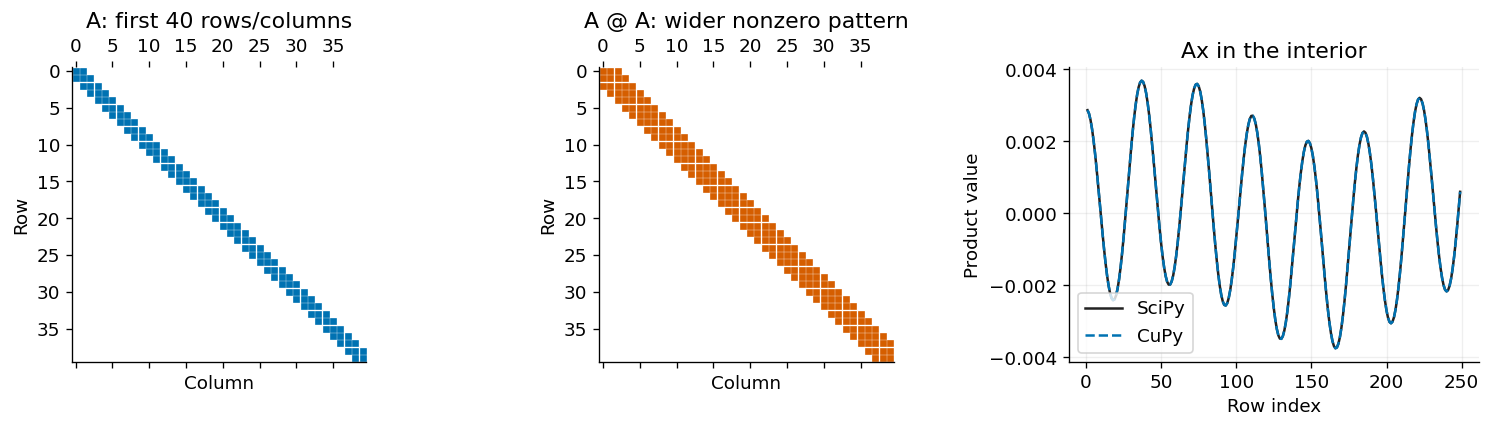

In [9]:
fig,axes=plt.subplots(1,3,figsize=(13,3.7))
preview=40
axes[0].spy(A_cpu[:preview,:preview],markersize=3,color='#0072B2')
axes[0].set(title='A: first 40 rows/columns',xlabel='Column',ylabel='Row')
axes[1].spy(S_host[:preview,:preview],markersize=3,color='#D55E00')
axes[1].set(title='A @ A: wider nonzero pattern',xlabel='Column',ylabel='Row')
indices=np.arange(1,min(250,N-1))
axes[2].plot(indices,y_cpu[indices],color='#222222',label='SciPy')
axes[2].plot(indices,y_gpu[indices],'--',color='#0072B2',label='CuPy')
axes[2].set(xlabel='Row index',ylabel='Product value',title='Ax in the interior')
axes[2].legend();axes[2].grid(alpha=.2)
fig.tight_layout();plt.show()

## Interpretation and execution status

Inputs and intermediate results stay on the device until explicitly retrieved for checking or plotting. These small examples establish correctness and illustrate the interface; they do not establish a speedup. Any later performance study must state transfer, allocation, and initialization costs.

**Preparation status:** delivered with empty outputs. Python syntax, mathematical checks, CPU reference calculations, and plot rendering were checked. GPU compilation and execution were unavailable during preparation; run on Colab for actual GPU results.

References: [CuPy sparse interfaces](https://docs.cupy.dev/en/stable/reference/scipy_sparse.html).

## Cleanup

After completing the examples, remove device-array references. CuPy may keep freed blocks in its memory pool. Rerun from data preparation before computing again.

In [10]:
cp.cuda.get_current_stream().synchronize()
del A_gpu, d_x, d_y, d_X, d_Y, S_gpu
print("Device array references released.")

Device array references released.
